# Algoritmo de Kruskal

Obtiene el árbol de expansión mínima de un grafo no dirigido ponderado: el conjunto de aristas que conecta todos los nodos con peso total mínimo. Ordena las aristas por peso y añade cada una si no forma ciclo, comprobándolo con Union-Find. Cuesta $O(E \log E)$.

## 1. Árbol de expansión mínima

Calcular el árbol de expansión mínima de una red de ciudades y su coste total.

In [1]:
class UnionFind:
    def __init__(self, nodos):
        self.padre = {n: n for n in nodos}

    def find(self, x):
        while self.padre[x] != x:
            # compresión por división a la mitad
            self.padre[x] = self.padre[self.padre[x]]
            x = self.padre[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        self.padre[rb] = ra
        return True

def kruskal(nodos, aristas):
    uf = UnionFind(nodos)
    return [(u, v, w) for u, v, w in sorted(aristas, key=lambda a: a[2]) if uf.union(u, v)]

nodos = ["Madrid", "Toledo", "Segovia", "Ávila", "Cuenca", "Guadalajara"]
aristas = [
    ("Madrid", "Toledo", 72), ("Madrid", "Segovia", 91), ("Madrid", "Ávila", 107),
    ("Madrid", "Cuenca", 167), ("Madrid", "Guadalajara", 60), ("Segovia", "Ávila", 67),
    ("Toledo", "Cuenca", 185), ("Guadalajara", "Cuenca", 135), ("Toledo", "Ávila", 137),
]
arbol = kruskal(nodos, aristas)
for arista in arbol:
    print(arista)
print("Coste total:", sum(w for _, _, w in arbol))

('Madrid', 'Guadalajara', 60)
('Segovia', 'Ávila', 67)
('Madrid', 'Toledo', 72)
('Madrid', 'Segovia', 91)
('Guadalajara', 'Cuenca', 135)
Coste total: 425


## 2. ¿Está conectado?

Si el grafo no es conexo, Kruskal devuelve un bosque con menos de $V - 1$ aristas. Usarlo para decidir si una red está totalmente conectada.

In [2]:
def conectado(nodos, aristas):
    return len(kruskal(nodos, aristas)) == len(nodos) - 1

print(conectado(nodos, aristas), conectado(nodos + ["Teruel"], aristas))

True False


## 3. Bosque de expansión mínima

En un grafo no conexo, Kruskal devuelve un árbol mínimo por cada componente (un bosque) con $V - C$ aristas, donde $C$ es el número de componentes. Separar los árboles del bosque de una red con varias componentes y comprobar en grafos pequeños aleatorios, conexos o no, que su peso coincide con el de la fuerza bruta: el mínimo entre los subconjuntos de $V - C$ aristas sin ciclos.

In [3]:
import random
from itertools import combinations

def componentes(nodos, aristas):
    uf = UnionFind(nodos)
    for u, v, _ in aristas:
        uf.union(u, v)
    grupos = {}
    for n in nodos:
        grupos.setdefault(uf.find(n), []).append(n)
    return list(grupos.values())

def arboles(nodos, aristas):
    bosque = kruskal(nodos, aristas)
    return [(grupo, [a for a in bosque if a[0] in grupo]) for grupo in componentes(nodos, aristas)]

def peso(aristas):
    return sum(w for _, _, w in aristas)

def sin_ciclos(nodos, aristas):
    uf = UnionFind(nodos)
    return all(uf.union(u, v) for u, v, _ in aristas)

def bosque_fuerza_bruta(nodos, aristas):
    tamano = len(nodos) - len(componentes(nodos, aristas))
    return min(peso(c) for c in combinations(aristas, tamano) if sin_ciclos(nodos, c))

red = list("ABCDEFGHI")
tramos = [("A", "B", 4), ("A", "C", 1), ("B", "C", 2), ("B", "D", 5), ("C", "D", 8),
          ("E", "F", 3), ("F", "G", 1), ("E", "G", 2), ("H", "I", 6)]
for grupo, arbol_grupo in arboles(red, tramos):
    print(grupo, arbol_grupo, "peso", peso(arbol_grupo))
assert peso(kruskal(red, tramos)) == bosque_fuerza_bruta(red, tramos)

random.seed(5)
for _ in range(300):
    n = random.randint(1, 7)
    ar = [(u, v, random.randint(1, 9)) for u, v in combinations(range(n), 2) if random.random() < 0.3]
    bosque = kruskal(range(n), ar)
    assert len(bosque) == n - len(componentes(range(n), ar))
    assert peso(bosque) == bosque_fuerza_bruta(range(n), ar)

['A', 'B', 'C', 'D'] [('A', 'C', 1), ('B', 'C', 2), ('B', 'D', 5)] peso 8
['E', 'F', 'G'] [('F', 'G', 1), ('E', 'G', 2)] peso 3
['H', 'I'] [('H', 'I', 6)] peso 6


## 4. Clustering con k grupos

Si Kruskal se detiene cuando quedan $k$ componentes, los grupos resultantes maximizan la **separación**, la menor distancia entre puntos de grupos distintos, que es el peso de la siguiente arista que Kruskal habría añadido. Agrupar 60 puntos aleatorios en 3 grupos, comprobar que equivale a quitar las $k - 1$ aristas más largas del árbol completo y que la separación es la menor distancia entre grupos, y dibujar el resultado.

Tamaños: [1, 20, 39]  separación: 2.351


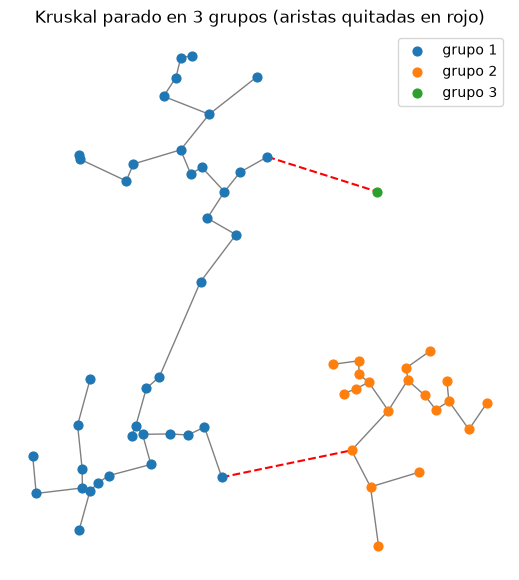

In [4]:
from math import dist
import matplotlib.pyplot as plt

def clustering(puntos, k):
    n = len(puntos)
    pares = sorted((dist(puntos[i], puntos[j]), i, j) for i, j in combinations(range(n), 2))
    uf, grupos = UnionFind(range(n)), n
    for d, i, j in pares:
        if uf.find(i) != uf.find(j):
            if grupos == k:
                return componentes(range(n), [(a, b, 0) for a, b in uf.padre.items()]), d
            uf.union(i, j)
            grupos -= 1
    return componentes(range(n), []), None

random.seed(12)
centros = [(0, 0), (6, 1), (2, 6)]
puntos = [(random.gauss(cx, 1), random.gauss(cy, 1)) for cx, cy in centros for _ in range(20)]
grupos, separacion = clustering(puntos, 3)
print("Tamaños:", sorted(map(len, grupos)), " separación:", round(separacion, 3))

completo = kruskal(range(len(puntos)), [(i, j, dist(puntos[i], puntos[j])) for i, j in combinations(range(len(puntos)), 2)])
completo.sort(key=lambda a: a[2])
recortado, quitadas = completo[:-2], completo[-2:]
assert {frozenset(g) for g in grupos} == {frozenset(g) for g in componentes(range(len(puntos)), recortado)}
grupo_de = {p: i for i, g in enumerate(grupos) for p in g}
assert separacion == min(dist(puntos[i], puntos[j]) for i, j in combinations(range(len(puntos)), 2)
                         if grupo_de[i] != grupo_de[j])

fig, eje = plt.subplots(figsize=(7, 7))
for u, v, _ in recortado:
    eje.plot(*zip(puntos[u], puntos[v]), color="gray", linewidth=1, zorder=1)
for u, v, _ in quitadas:
    eje.plot(*zip(puntos[u], puntos[v]), color="red", linewidth=1.5, linestyle="--", zorder=1)
for i, g in enumerate(grupos):
    eje.scatter(*zip(*(puntos[p] for p in g)), s=40, zorder=2, label=f"grupo {i + 1}")
eje.legend()
eje.set_title(f"Kruskal parado en 3 grupos (aristas quitadas en rojo)")
eje.set_aspect("equal")
eje.axis("off")
plt.show()